In [1]:
# ==========================================================
# SECTION 1 - IMPORT LIBRARIES
# ==========================================================

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

sns.set_style("whitegrid")

In [ ]:
# ==========================================================
# SECTION 1A - REUSABLE FUNCTIONS
# ==========================================================

In [24]:
def load_dataset(path):
    """
    Load CSV dataset.
    """
    return pd.read_csv(path)

In [25]:
def descriptive_statistics(df, columns):

    stats = pd.DataFrame()

    for col in columns:

        stats.loc[col, "Mean"] = df[col].mean()
        stats.loc[col, "Median"] = df[col].median()
        stats.loc[col, "Mode"] = df[col].mode()[0]
        stats.loc[col, "Variance"] = df[col].var()

    return stats

In [26]:
def detect_outliers_iqr(series):

    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)

    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    return series[
        (series < lower)
        |
        (series > upper)
    ]

In [27]:
def evaluate_model(y_true, y_pred):

    mae = mean_absolute_error(
        y_true,
        y_pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_pred
        )
    )

    r2 = r2_score(
        y_true,
        y_pred
    )

    return {
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }

In [28]:
# ==========================================================
# SECTION 2 - UPLOAD FILES
# ==========================================================

uploaded = files.upload()

Saving Daily shelter overnight occupancy.csv to Daily shelter overnight occupancy (1).csv
Saving daily-shelter-overnight-service-occupancy-capacity-2025.csv to daily-shelter-overnight-service-occupancy-capacity-2025 (1).csv
Saving Deaths of Shelter Residents (1).csv to Deaths of Shelter Residents (1) (1).csv
Saving Deaths of Shelter Residents Mean Age.csv to Deaths of Shelter Residents Mean Age (1).csv
Saving Homeless deaths by cause.csv to Homeless deaths by cause (1).csv
Saving Homeless deaths by demographics.csv to Homeless deaths by demographics (1).csv
Saving Homeless deaths by month.csv to Homeless deaths by month (1).csv
Saving Homeless deaths by Setting.csv to Homeless deaths by Setting (1).csv
Saving toronto-shelter-system-flow (1).csv to toronto-shelter-system-flow (1) (1).csv


In [29]:
# ==========================================================
# SECTION 3 - LOAD DATASETS
# ==========================================================

deaths = pd.read_csv(
    "Deaths of Shelter Residents (1).csv"
)

flow = pd.read_csv(
    "toronto-shelter-system-flow (1).csv"
)

occupancy = pd.read_csv(
    "daily-shelter-overnight-service-occupancy-capacity-2025.csv"
)

homeless_month = pd.read_csv(
    "Homeless deaths by month.csv"
)

homeless_cause = pd.read_csv(
    "Homeless deaths by cause.csv"
)

homeless_demo = pd.read_csv(
    "Homeless deaths by demographics.csv"
)

homeless_setting = pd.read_csv(
    "Homeless deaths by Setting.csv"
)

mean_age = pd.read_csv(
    "Deaths of Shelter Residents Mean Age.csv"
)

print("Deaths:", deaths.shape)
print("Flow:", flow.shape)
print("Occupancy:", occupancy.shape)

Deaths: (235, 7)
Flow: (804, 20)
Occupancy: (51543, 32)


In [30]:
# ==========================================================
# SECTION 4 - DATA PROFILING
# ==========================================================

datasets = {
    "Deaths": deaths,
    "Flow": flow,
    "Occupancy": occupancy
}

for name, df in datasets.items():

    print("\n" + "="*60)
    print(name)

    print("Rows:", df.shape[0])
    print("Columns:", df.shape[1])

    print("\nMissing Values:")
    print(
        df.isnull().sum()
        [df.isnull().sum() > 0]
        .sort_values(ascending=False)
    )

    print(
        "\nDuplicate Rows:",
        df.duplicated().sum()
    )


Deaths
Rows: 235
Columns: 7

Missing Values:
Transgender/Non-binary/Two-Spirit    156
dtype: int64

Duplicate Rows: 0

Flow
Rows: 804
Columns: 20

Missing Values:
Series([], dtype: int64)

Duplicate Rows: 0

Occupancy
Rows: 51543
Columns: 32

Missing Values:
UNOCCUPIED_ROOMS         38762
CAPACITY_FUNDING_ROOM    38762
OCCUPIED_ROOMS           38762
UNAVAILABLE_ROOMS        38762
OCCUPANCY_RATE_ROOMS     38762
CAPACITY_ACTUAL_ROOM     38762
CAPACITY_ACTUAL_BED      12781
UNOCCUPIED_BEDS          12781
OCCUPIED_BEDS            12781
UNAVAILABLE_BEDS         12781
CAPACITY_FUNDING_BED     12781
OCCUPANCY_RATE_BEDS      12781
LOCATION_PROVINCE         2829
LOCATION_CITY             2359
LOCATION_ADDRESS          2346
LOCATION_POSTAL_CODE      2346
PROGRAM_MODEL                4
dtype: int64

Duplicate Rows: 0


In [31]:
# ==========================================================
# SECTION 5 - DATA PREPARATION
# ==========================================================

month_map = {
    "Jan":1,
    "Feb":2,
    "Mar":3,
    "Apr":4,
    "May":5,
    "Jun":6,
    "Jul":7,
    "Aug":8,
    "Sep":9,
    "Oct":10,
    "Nov":11,
    "Dec":12
}

In [32]:
deaths["Month_Num"] = (
    deaths["Month"]
    .map(month_map)
)

deaths["Date"] = pd.to_datetime(
    dict(
        year=deaths["Year"],
        month=deaths["Month_Num"],
        day=1
    )
)


In [33]:
flow["Date"] = pd.to_datetime(
    flow["date(mmm-yy)"],
    format="%b-%y"
)

In [34]:
flow_all = flow[
    flow["population_group"]
    == "All Population"
].copy()

In [35]:
merged = pd.merge(
    deaths[
        ["Date","Total decedents"]
    ].rename(
        columns={
            "Total decedents":"Deaths"
        }
    ),
    flow_all,
    on="Date",
    how="inner"
)

print(merged.shape)
merged.head()

(101, 22)


,Date,Deaths,_id,date(mmm-yy),population_group,returned_from_housing,returned_to_shelter,newly_identified,moved_to_housing,became_inactive,...,age16-24,age25-34,age35-44,age45-54,age55-64,age65over,gender_male,gender_female,"gender_transgender,non-binary_or_two_spirit",population_group_percentage
0,2018-01-01,4,1,Jan-18,All Population,46,494,1106,508,862,...,1111,1341,1560,1318,973,422,4963,2912,83,100.0%
1,2018-02-01,4,8,Feb-18,All Population,78,481,947,489,757,...,1094,1392,1579,1399,965,432,5093,2959,80,100.0%
2,2018-03-01,1,15,Mar-18,All Population,64,489,1226,533,736,...,1115,1487,1727,1460,969,435,5389,3133,85,100.0%
3,2018-04-01,2,22,Apr-18,All Population,59,518,1305,652,760,...,1126,1554,1823,1476,983,456,5631,3312,90,100.0%
4,2018-05-01,1,29,May-18,All Population,50,484,1469,575,882,...,1153,1644,1946,1502,985,456,5838,3583,95,100.0%


In [36]:
# ==========================================================
# SECTION 6 - DESCRIPTIVE STATISTICS
# ==========================================================

variables = [
    "Deaths",
    "actively_homeless",
    "returned_to_shelter",
    "newly_identified",
    "moved_to_housing"
]

stats_table = pd.DataFrame()

for col in variables:

    stats_table.loc[col,"Mean"] = merged[col].mean()

    stats_table.loc[col,"Median"] = merged[col].median()

    stats_table.loc[col,"Mode"] = merged[col].mode()[0]

    stats_table.loc[col,"Variance"] = merged[col].var()

stats_table.round(2)

,Mean,Median,Mode,Variance
Deaths,6.09,6.0,6.0,15.72
actively_homeless,9650.74,9782.0,9557.0,1108026.19
returned_to_shelter,372.99,389.0,154.0,18002.61
newly_identified,789.42,783.0,368.0,77050.21
moved_to_housing,467.13,448.0,246.0,31179.59


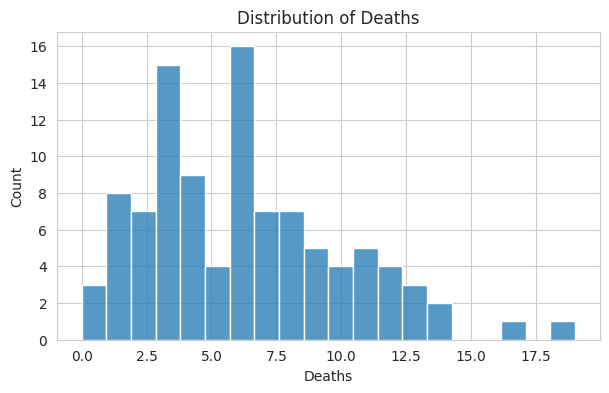

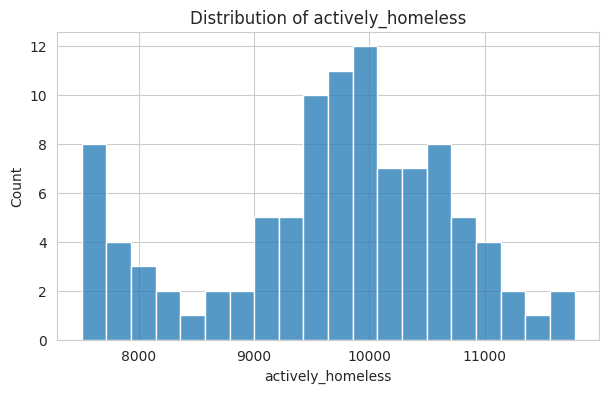

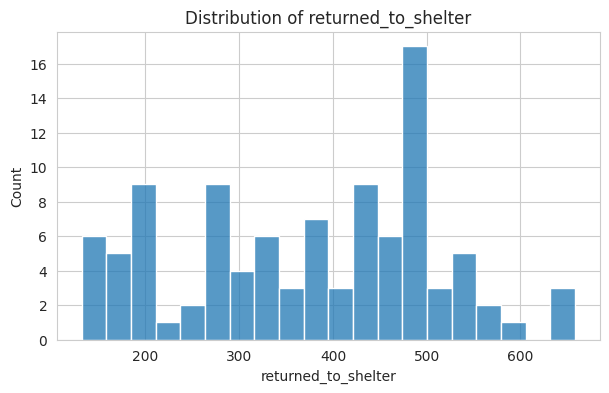

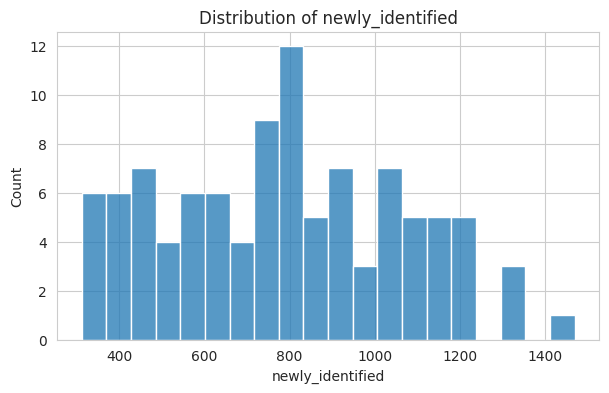

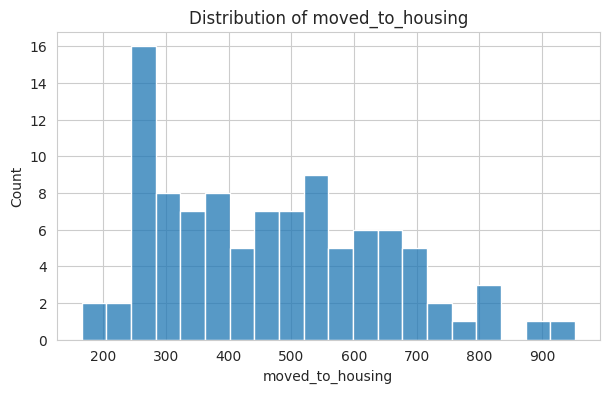

In [37]:
for col in variables:

    plt.figure(figsize=(7,4))

    sns.histplot(
        merged[col],
        bins=20
    )

    plt.title(f"Distribution of {col}")

    plt.show()

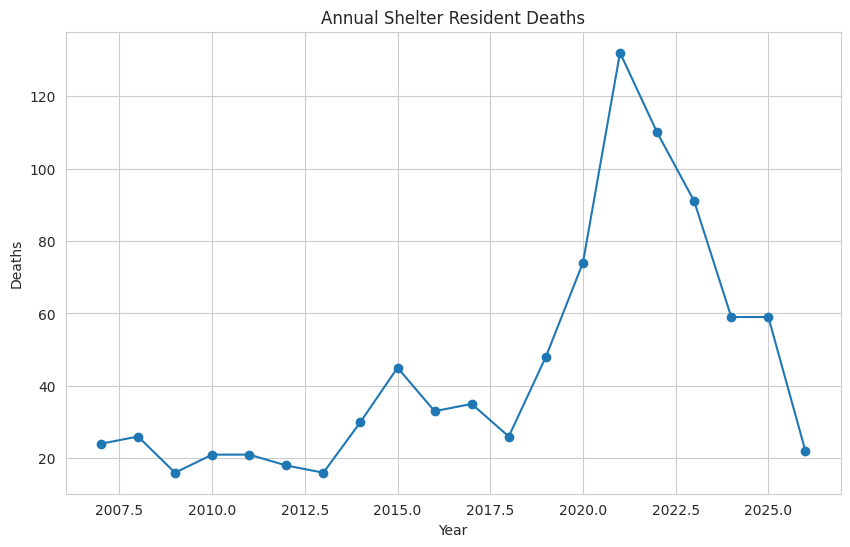

In [49]:
# ==========================================================
# SECTION 6A.1 - ANNUAL DEATH TRENDS
# ==========================================================

annual_deaths = (

    deaths.groupby("Year")["Total decedents"]
    .sum()
    .reset_index()

)

plt.figure(figsize=(10,6))

plt.plot(
    annual_deaths["Year"],
    annual_deaths["Total decedents"],
    marker="o"
)

plt.title(
    "Annual Shelter Resident Deaths"
)

plt.xlabel("Year")

plt.ylabel("Deaths")

plt.grid(True)

plt.show()

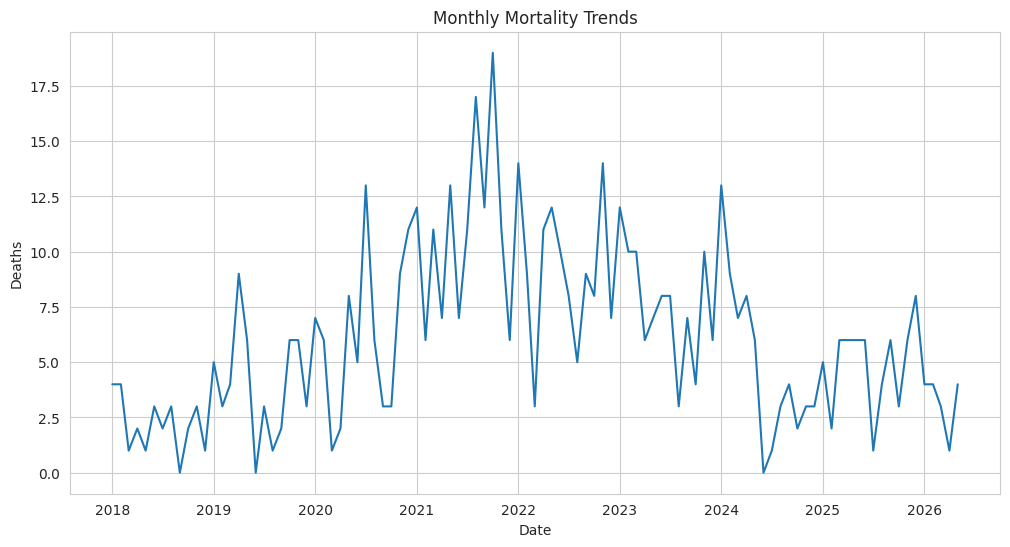

In [50]:
# ==========================================================
# SECTION 6A.2 - MONTHLY DEATH TRENDS
# ==========================================================

monthly_deaths = merged[
    ["Date","Deaths"]
].sort_values("Date")

plt.figure(figsize=(12,6))

plt.plot(
    monthly_deaths["Date"],
    monthly_deaths["Deaths"]
)

plt.title(
    "Monthly Mortality Trends"
)

plt.xlabel("Date")

plt.ylabel("Deaths")

plt.grid(True)

plt.show()

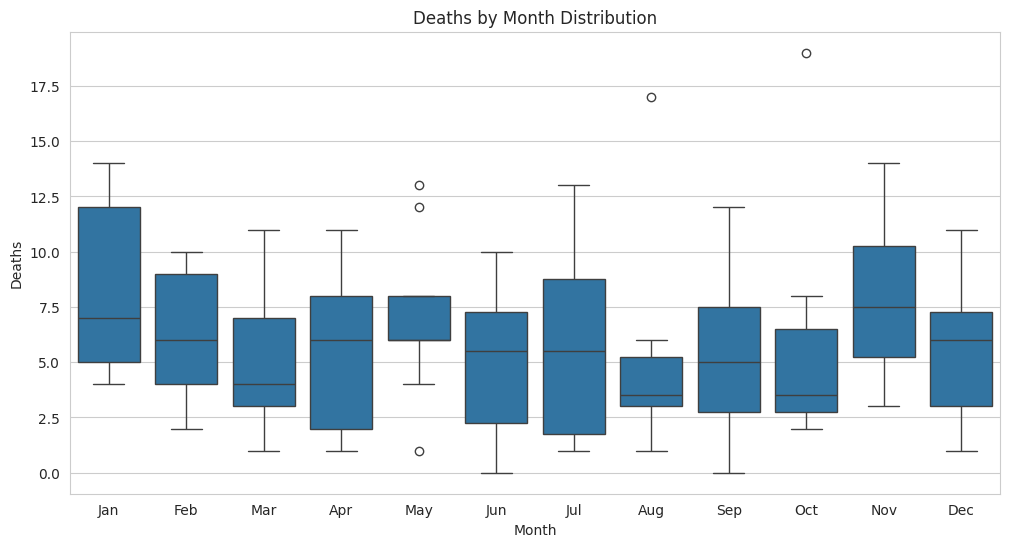

In [52]:
# ==========================================================
# SECTION 6A.3 - MONTHLY MORTALITY PATTERNS
# ==========================================================

monthly_deaths = merged.copy()

monthly_deaths["Month"] = (
    monthly_deaths["Date"]
    .dt.strftime("%b")
)

month_order = [
    "Jan","Feb","Mar","Apr",
    "May","Jun","Jul","Aug",
    "Sep","Oct","Nov","Dec"
]

plt.figure(figsize=(12,6))

sns.boxplot(
    data=monthly_deaths,
    x="Month",
    y="Deaths",
    order=month_order
)

plt.title(
    "Deaths by Month Distribution"
)

plt.xlabel("Month")

plt.ylabel("Deaths")

plt.show()

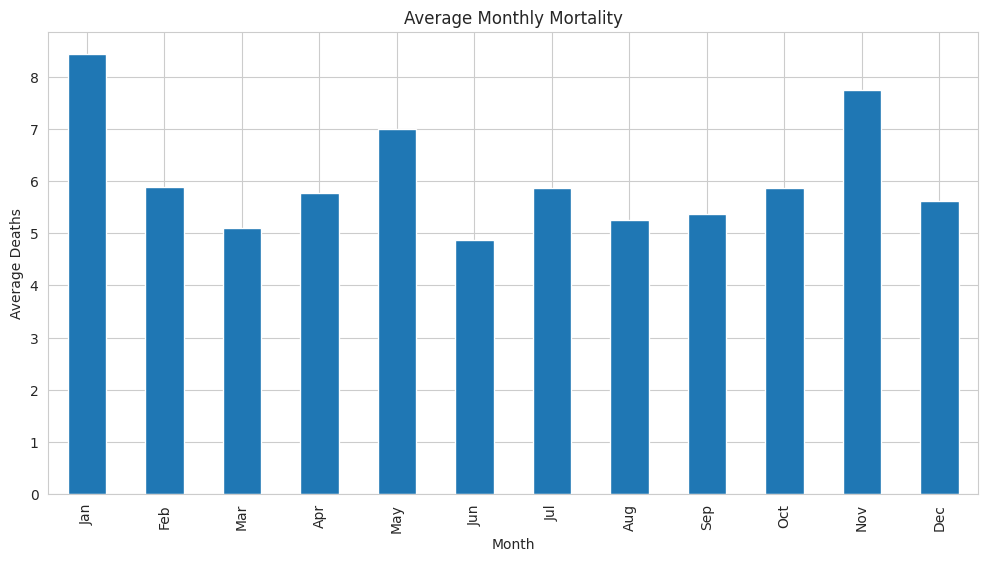

In [53]:
# ==========================================================
# SECTION 6A.5 - AVERAGE DEATHS BY MONTH
# ==========================================================

avg_month = (

    monthly_deaths
    .groupby("Month")["Deaths"]
    .mean()
    .reindex(month_order)

)

plt.figure(figsize=(12,6))

avg_month.plot(
    kind="bar"
)

plt.title(
    "Average Monthly Mortality"
)

plt.ylabel(
    "Average Deaths"
)

plt.xlabel(
    "Month"
)

plt.show()

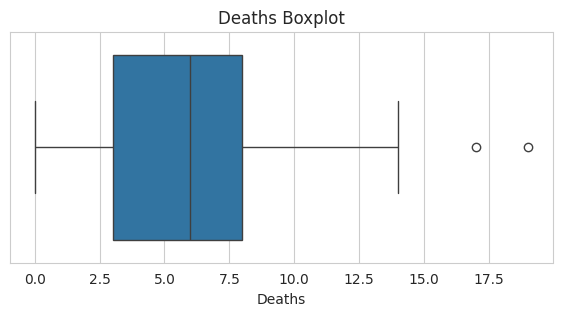

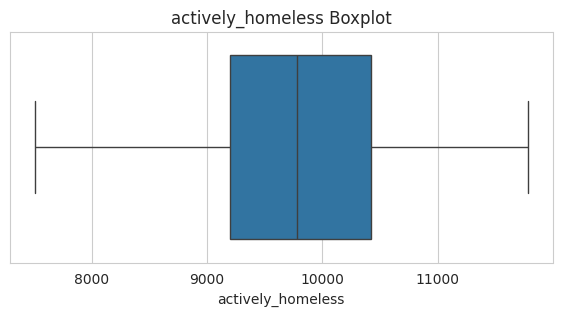

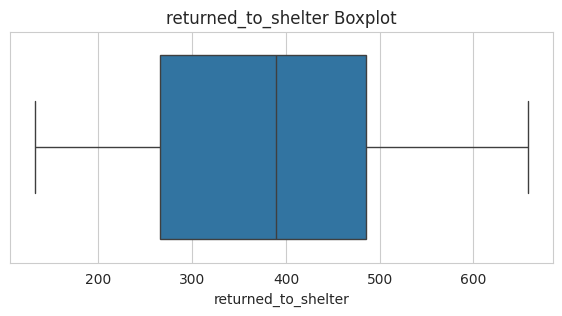

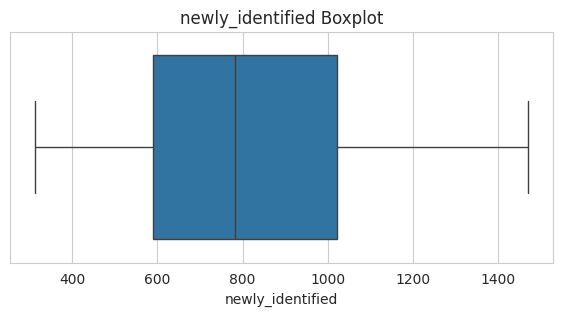

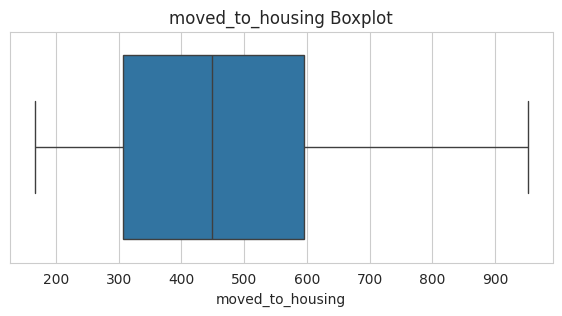

In [38]:
for col in variables:

    plt.figure(figsize=(7,3))

    sns.boxplot(
        x=merged[col]
    )

    plt.title(f"{col} Boxplot")

    plt.show()

In [39]:
Q1 = merged["Deaths"].quantile(0.25)

Q3 = merged["Deaths"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR

upper = Q3 + 1.5 * IQR

outliers = merged[
    (merged["Deaths"] < lower)
    |
    (merged["Deaths"] > upper)
]

outliers


,Date,Deaths,_id,date(mmm-yy),population_group,returned_from_housing,returned_to_shelter,newly_identified,moved_to_housing,became_inactive,...,age16-24,age25-34,age35-44,age45-54,age55-64,age65over,gender_male,gender_female,"gender_transgender,non-binary_or_two_spirit",population_group_percentage
43,2021-08-01,17,309,Aug-21,All Population,104,452,685,306,728,...,972,1711,1813,1490,1211,581,5368,2958,153,100.0%
45,2021-10-01,19,325,Oct-21,All Population,80,450,850,270,823,...,1052,1744,1921,1535,1298,595,5665,3175,152,100.0%


# Correlation analysis is performed to evaluate
# whether shelter-system indicators move together
# with mortality levels over time.

In [40]:
corr_vars = [
    "Deaths",
    "actively_homeless",
    "returned_to_shelter",
    "newly_identified",
    "moved_to_housing"
]

corr = merged[corr_vars].corr()

corr.round(3)


,Deaths,actively_homeless,returned_to_shelter,newly_identified,moved_to_housing
Deaths,1.000,-0.182,0.050,-0.142,-0.400
actively_homeless,-0.182,1.000,-0.324,0.090,0.092
returned_to_shelter,0.050,-0.324,1.000,0.631,0.473
newly_identified,-0.142,0.090,0.631,1.000,0.703
moved_to_housing,-0.400,0.092,0.473,0.703,1.000


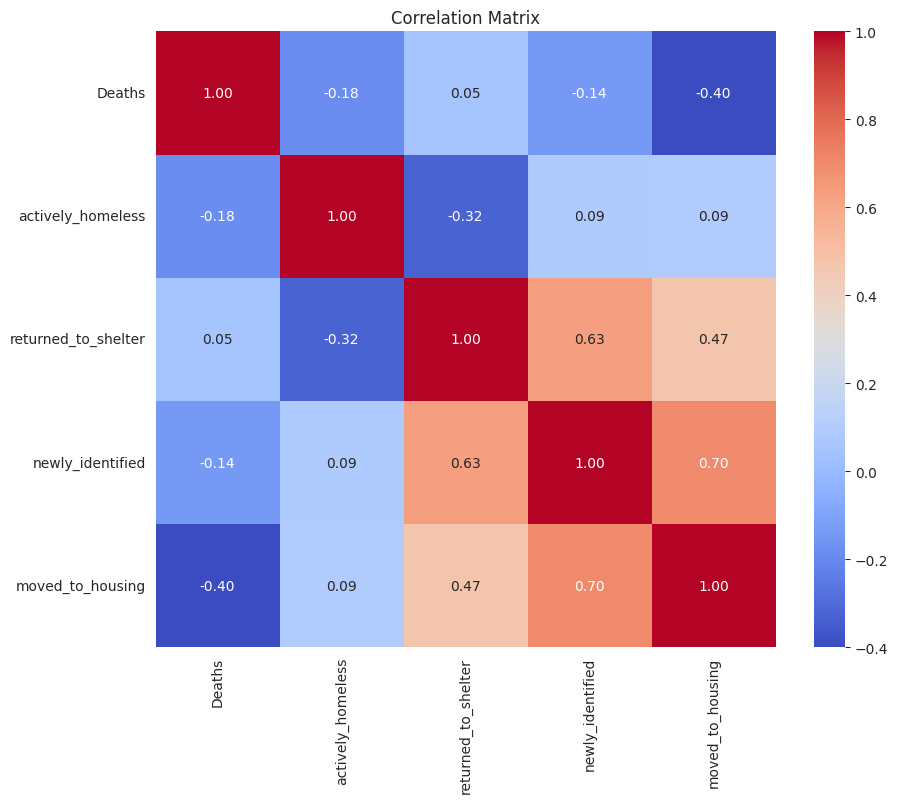

In [41]:
plt.figure(figsize=(10,8))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title(
    "Correlation Matrix"
)

plt.show()

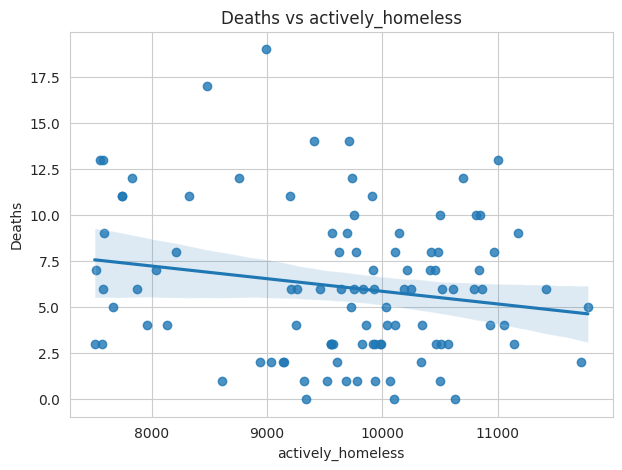

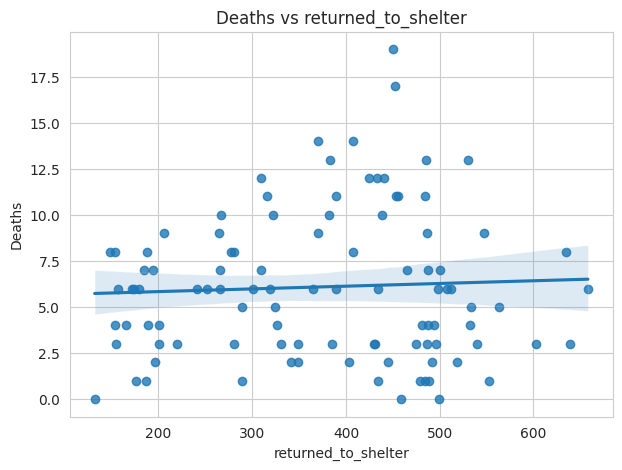

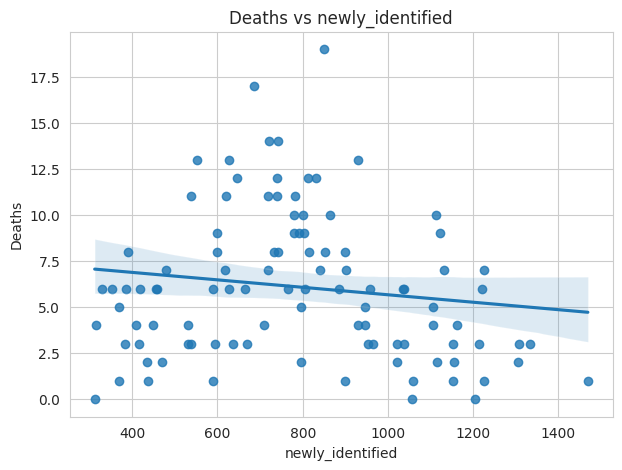

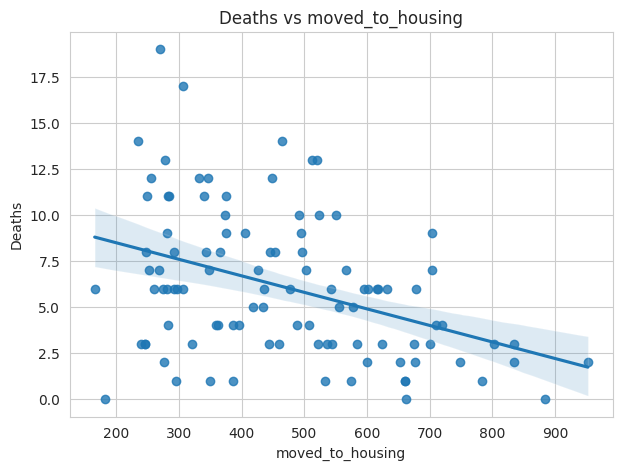

In [42]:
drivers = [
    "actively_homeless",
    "returned_to_shelter",
    "newly_identified",
    "moved_to_housing"
]

for col in drivers:

    plt.figure(figsize=(7,5))

    sns.regplot(
        data=merged,
        x=col,
        y="Deaths"
    )

    plt.title(
        f"Deaths vs {col}"
    )

    plt.show()

In [43]:
# ==========================================================
# SECTION 9 - MODELING DATASET
# ==========================================================

features = [
    "actively_homeless",
    "returned_to_shelter",
    "newly_identified",
    "moved_to_housing"
]

X = merged[features]

y = merged["Deaths"]

# Chronological splitting prevents future data
# from appearing in the training set and helps
# avoid temporal data leakage.

In [44]:
split_index = int(
    len(merged) * 0.80
)

X_train = X.iloc[:split_index]

X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]

y_test = y.iloc[split_index:]

In [45]:
lr = LinearRegression()

lr.fit(
    X_train,
    y_train
)

pred_lr = lr.predict(
    X_test
)

mae_lr = mean_absolute_error(
    y_test,
    pred_lr
)

rmse_lr = np.sqrt(
    mean_squared_error(
        y_test,
        pred_lr
    )
)

r2_lr = r2_score(
    y_test,
    pred_lr
)

# Random Forest is used to capture possible
# non-linear relationships between shelter-system
# variables and mortality outcomes.

In [46]:
rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf.fit(
    X_train,
    y_train
)

pred_rf = rf.predict(
    X_test
)

mae_rf = mean_absolute_error(
    y_test,
    pred_rf
)

rmse_rf = np.sqrt(
    mean_squared_error(
        y_test,
        pred_rf
    )
)

r2_rf = r2_score(
    y_test,
    pred_rf
)

In [47]:
results = pd.DataFrame({

    "Model":[
        "Linear Regression",
        "Random Forest"
    ],

    "MAE":[
        mae_lr,
        mae_rf
    ],

    "RMSE":[
        rmse_lr,
        rmse_rf
    ],

    "R2":[
        r2_lr,
        r2_rf
    ]
})

results.round(3)

,Model,MAE,RMSE,R2
0,Linear Regression,3.708,4.176,-4.190
1,Random Forest,3.057,3.644,-2.952


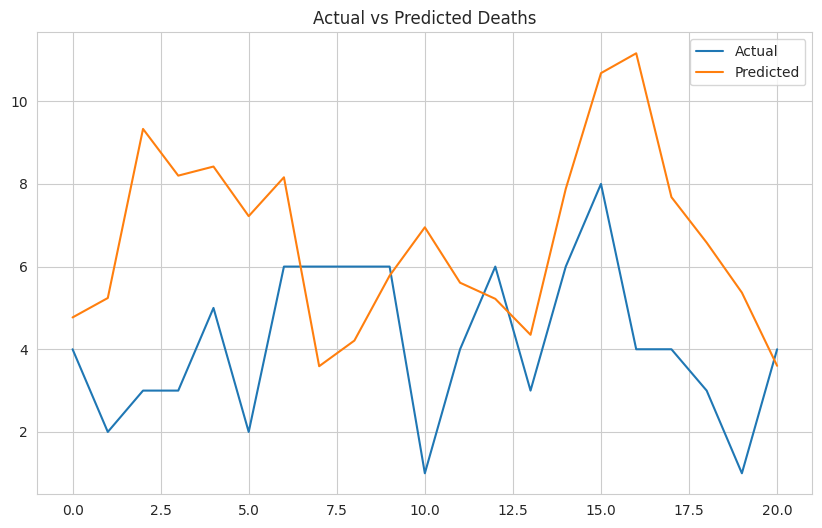

In [48]:
plt.figure(figsize=(10,6))

plt.plot(
    y_test.values,
    label="Actual"
)

plt.plot(
    pred_rf,
    label="Predicted"
)

plt.legend()

plt.title(
    "Actual vs Predicted Deaths"
)

plt.show()

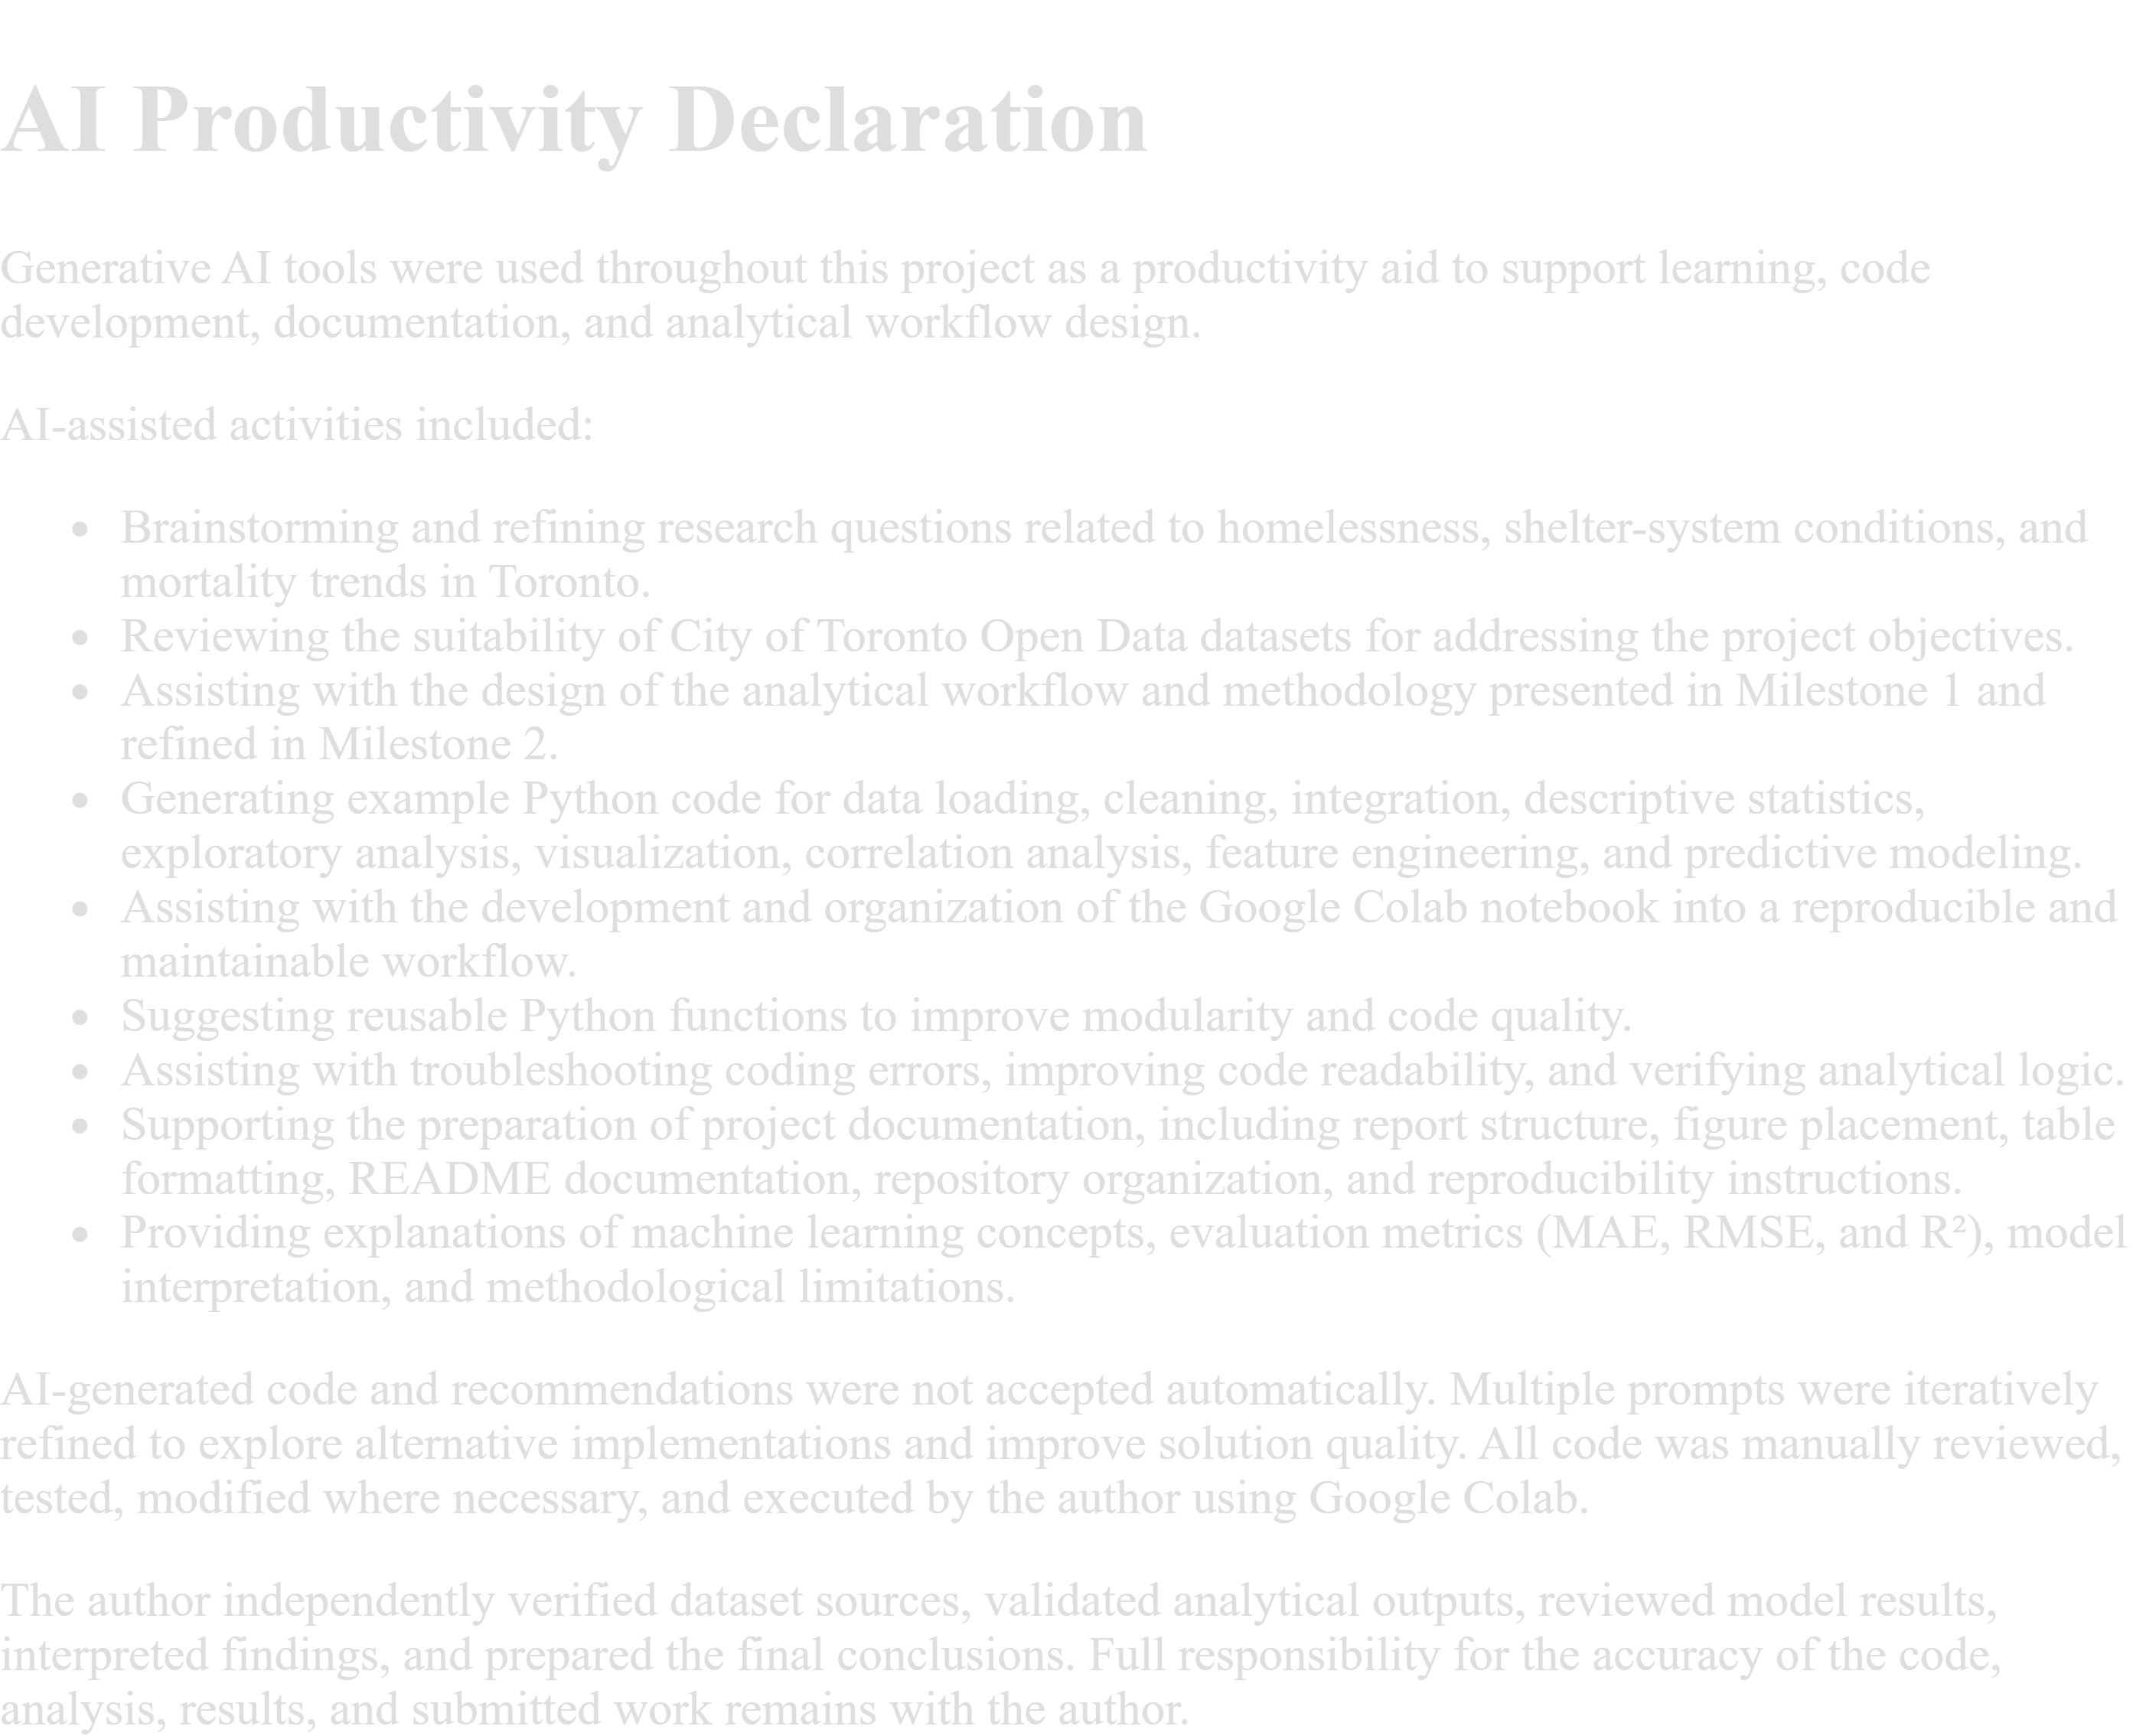